In [37]:
!pip install ucimlrepo

In [38]:
from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances_argmin_min

import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram

In [39]:
# breast cancer dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
X_breast = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

In [40]:
# waveform dataset
waveform_database_generator_version_1 = fetch_ucirepo(id=107)

# data (as pandas dataframes)
X_waveform = waveform_database_generator_version_1.data.features
y_waveform = waveform_database_generator_version_1.data.targets

## Part 1



### 1. Perform k-means clustering on different datasets (use k = 1, 2, 3,..., 6 for breast cancer dataset and use k = 2, 3, ..., 6 for waveform dataset)



In [41]:
breast_sse = []

for k in range(1,7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_breast)

    breast_sse.append(kmeans.inertia_)   # SSE

print("Breast cancer SSE values:")
for k, sse in zip(range(1,7), breast_sse):
    print(f"k = {k}, SSE = {sse:.4f}")

Breast cancer SSE values:
k = 1, SSE = 256677243.9542
k = 2, SSE = 77943099.8783
k = 3, SSE = 47264841.9168
k = 4, SSE = 29226541.6520
k = 5, SSE = 20539877.6221
k = 6, SSE = 16573867.0192


In [42]:
waveform_sse = []

for k in range(2,7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_waveform)

    waveform_sse.append(kmeans.inertia_)   # SSE

print("Waveform SSE values:")
for k, sse in zip(range(2,7), waveform_sse):
    print(f"k = {k}, SSE = {sse:.4f}")

Waveform SSE values:
k = 2, SSE = 167123.9502
k = 3, SSE = 133119.2355
k = 4, SSE = 123773.9619
k = 5, SSE = 117196.3422
k = 6, SSE = 112458.7869


### 2. Calculate the SSE and plot sum-of-squared errors (SSE) versus k


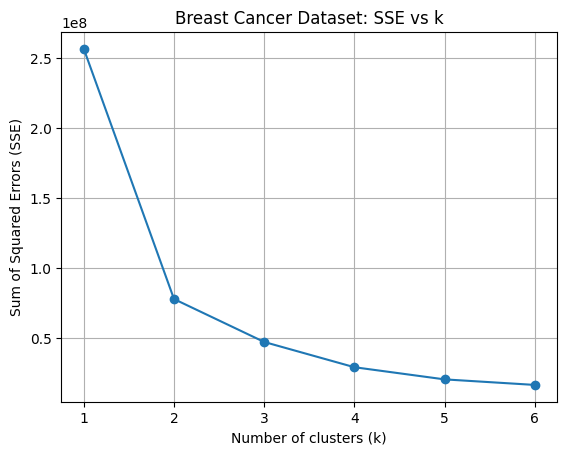

In [43]:
#Plotting breast cancer dataset
plt.plot(range(1,7), breast_sse, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.title("Breast Cancer Dataset: SSE vs k")
plt.xticks(range(1,7))
plt.grid(True)
plt.show()

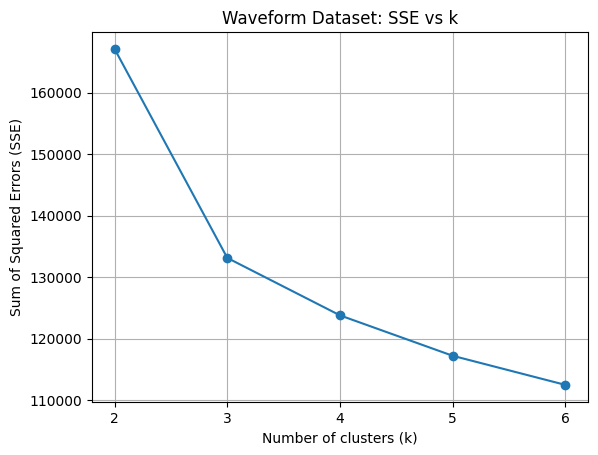

In [44]:
#Plotting waveform dataset
plt.plot(range(2,7), waveform_sse, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.title("Waveform Dataset: SSE vs k")
plt.xticks(range(2,7))
plt.grid(True)
plt.show()

### 3. Find the best k using the elbow approach (see the tutorial)


From the graphs above, it looks like the best k for the breast cancer data set is 2 and the best k for the waveform dataset is 3.

### 4.   For k-means model built with the best k: find the centers of clusters and find the top-5 closest points to the center of each cluster

In [45]:
def analyze_best_kmeans(X, best_k, dataset_name):
    # Fit the best model
    kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    kmeans.fit(X)

    print(f"{dataset_name} (k={best_k})")

    # Get cluster centers
    centers = kmeans.cluster_centers_
    print(f"Cluster Centers:\n{centers}\n")

    # Calculate distances from all points to all cluster centers
    distances = kmeans.transform(X)

    # Find top 5 closest points for each cluster
    for cluster_idx in range(best_k):
        # Extract distances to the current cluster center
        dist_to_cluster = distances[:, cluster_idx]

        # Get indices of the 5 points with the smallest distances
        closest_indices = np.argsort(dist_to_cluster)[:5]

        print(f"Cluster {cluster_idx} - Top 5 closest points (row indices): {closest_indices.tolist()}")
        print(f"Distances to center: {dist_to_cluster[closest_indices]}\n")

# Run analysis for both datasets
analyze_best_kmeans(X_breast, 2, "Breast Cancer")
analyze_best_kmeans(X_waveform, 3, "Waveform")

Breast Cancer (k=2)
Cluster Centers:
[[1.93799237e+01 2.16945802e+01 1.28231298e+02 1.18592977e+03
  1.01294580e-01 1.48612977e-01 1.76939466e-01 1.00698779e-01
  1.91539695e-01 6.06029008e-02 7.42803817e-01 1.22253817e+00
  5.25058015e+00 9.56781679e+01 6.59868702e-03 3.21766947e-02
  4.24197710e-02 1.56739847e-02 2.03039695e-02 3.95338931e-03
  2.37094656e+01 2.89126718e+01 1.58496183e+02 1.75302290e+03
  1.40424733e-01 3.57757710e-01 4.49306107e-01 1.92431069e-01
  3.11881679e-01 8.61654962e-02]
 [1.25562991e+01 1.85703653e+01 8.11234703e+01 4.96061872e+02
  9.48844977e-02 9.10998174e-02 6.24377642e-02 3.34325434e-02
  1.78057991e-01 6.34540183e-02 3.04190868e-01 1.21515320e+00
  2.15288059e+00 2.37852922e+01 7.17326256e-03 2.34746895e-02
  2.87455128e-02 1.06363242e-02 2.06135799e-02 3.74750297e-03
  1.40439018e+01 2.47095434e+01 9.19375114e+01 6.19647945e+02
  1.29959110e-01 2.23311758e-01 2.19214947e-01 9.13298425e-02
  2.83553653e-01 8.32819406e-02]]

Cluster 0 - Top 5 closest p

## Part 2

### 1. Perform hierarchical  clustering (Single Link, Complete Link, and Group Average ) on different data sets

### 2. Draw a dendrogram diagram for each case (use appropriate options of the dendrogram to draw a nice visualization). See resource (3).

##### Breast Cancer Dataset

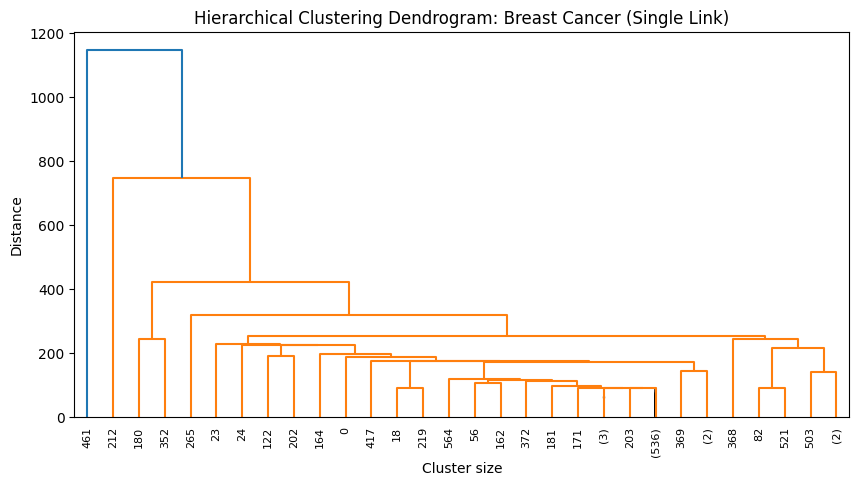

In [46]:
# Perform Single Link hierarchical clustering on Breast Cancer dataset
Z_bc_single = linkage(X_breast, method='single')

# Draw the dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    Z_bc_single,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=8.,
    show_contracted=True,
)
plt.title('Hierarchical Clustering Dendrogram: Breast Cancer (Single Link)')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

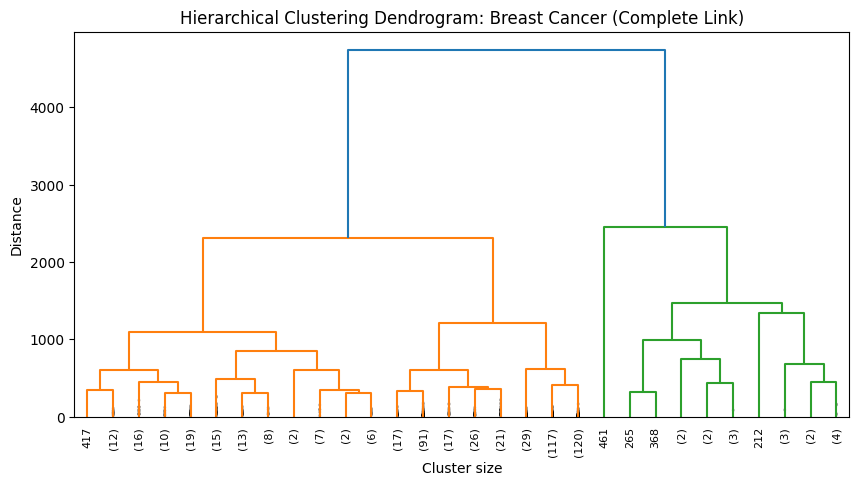

In [47]:
# Complete Link
Z_bc_complete = linkage(X_breast, method='complete')

# Draw the dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    Z_bc_complete,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=8.,
    show_contracted=True,
)
plt.title('Hierarchical Clustering Dendrogram: Breast Cancer (Complete Link)')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

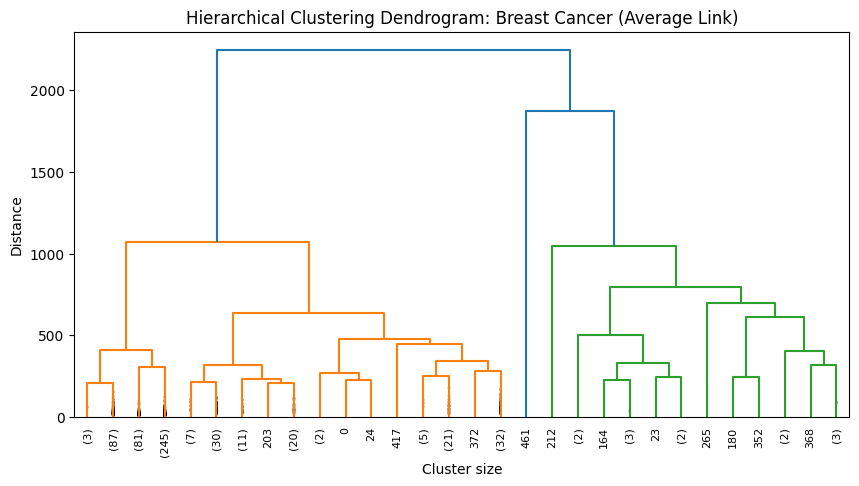

In [48]:
# Whole Average
Z_bc_average = linkage(X_breast, method='average')

# Draw the dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    Z_bc_average,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=8.,
    show_contracted=True,
)
plt.title('Hierarchical Clustering Dendrogram: Breast Cancer (Average Link)')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

##### Waveform Dataset

In [49]:
import sys
sys.setrecursionlimit(10000)

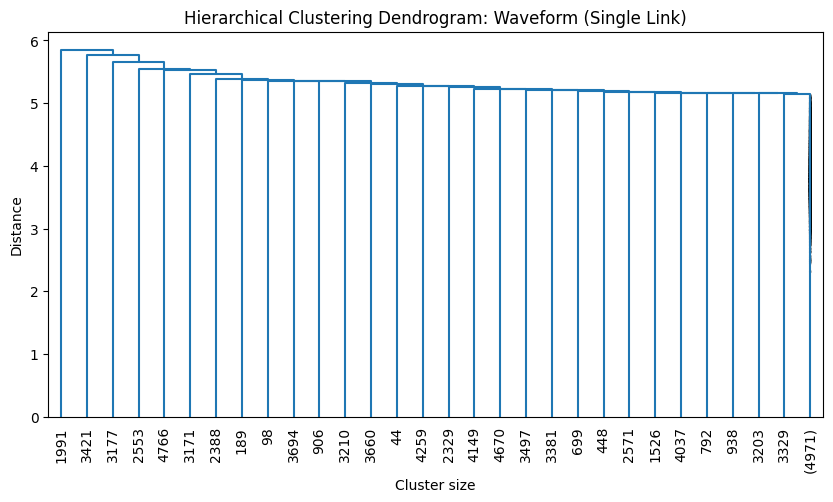

In [50]:
# Perform Single Link hierarchical clustering on Waveform dataset
Z_wf_single = linkage(X_waveform, method='single')

# Draw the dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    Z_wf_single,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title('Hierarchical Clustering Dendrogram: Waveform (Single Link)')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

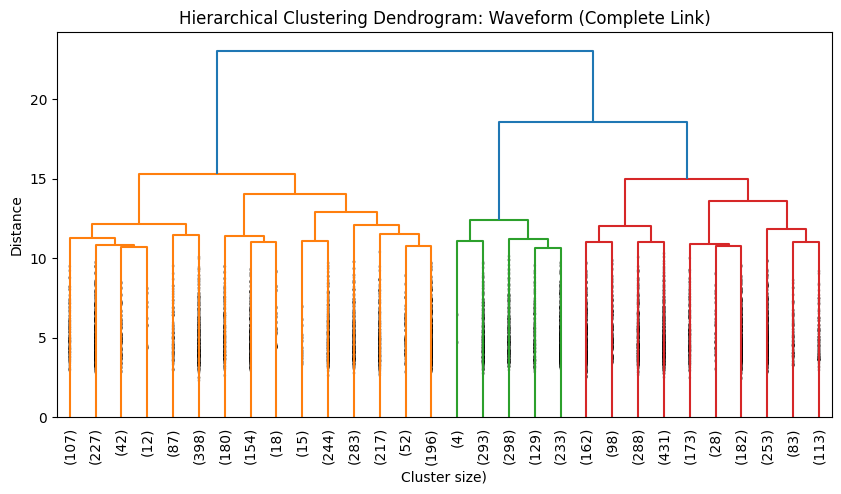

In [51]:
# Perform Complete Link hierarchical clustering on Waveform dataset
Z_wf_complete = linkage(X_waveform, method='complete')

# Draw the dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    Z_wf_complete,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title('Hierarchical Clustering Dendrogram: Waveform (Complete Link)')
plt.xlabel('Cluster size)')
plt.ylabel('Distance')
plt.show()

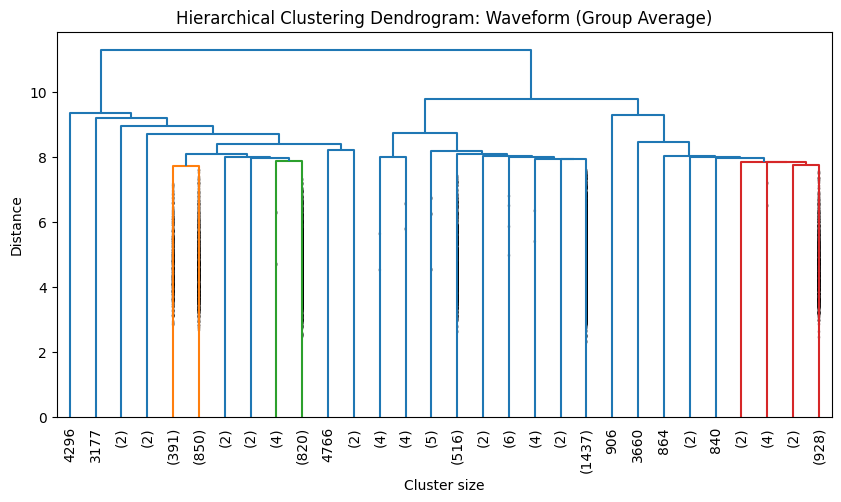

In [52]:
# Perform Group Average hierarchical clustering on Waveform dataset
Z_wf_average = linkage(X_waveform, method='average')

# Draw the dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    Z_wf_average,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title('Hierarchical Clustering Dendrogram: Waveform (Group Average)')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()